# Reproducing the tables and figures of the paper
This notebook shows the results of the paper: Tables 2 to 11 and the figures of Section 4. It does not train any model. It loads the saved weights in `data/` and the survey answers in `data/AI Predictive Maintenance.csv`.

Run the cells from top to bottom. With the cached results in `results/fd001/` it takes a few minutes. If you delete that folder, the explanation analysis is computed again (about 15 minutes on a laptop CPU). Start Jupyter from the `notebooks/` folder.

In [1]:
import os, sys, json, pickle, subprocess
import numpy as np
import pandas as pd
from IPython.display import Image, display

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
pd.set_option("display.width", 160)
assert os.path.basename(os.getcwd()) == "notebooks", "start Jupyter from the notebooks/ folder"

import xai_analysis as XA
from rul_common import load_fd001, load_models

RES = "../results/fd001"

def run(script, *args):
    """run one of the scripts of this folder and print what it prints"""
    r = subprocess.run([sys.executable, script, *args], capture_output=True, text=True)
    print(r.stdout[-5000:])
    if r.returncode:
        print(r.stderr[-2000:])
    r.check_returncode()

## 1. Data and models
The three models are the saved weights `data/model.pth` (LSTM), `data/cnn_model.pth` (CNN) and `data/hybrid_model.pth` (hybrid). Table 3 of the paper lists their size and training settings.

In [2]:
data = load_fd001()
lstm, cnn, hybrid = load_models()
print("training windows:", data["X_train_shape"][0], "| validation windows:", len(data["X_val"]),
      "| training engines:", len(data["train_ids"]), "| validation engines:", len(data["val_ids"]))
table3 = pd.DataFrame({
    "LSTM": [96, 2, 0.2, "1e-3", "30 / 5", sum(p.numel() for p in lstm.parameters())],
    "CNN": ["32, 16", "2 conv + 2 FC", 0.2, "1e-3", "30 / 5", sum(p.numel() for p in cnn.parameters())],
    "Hybrid": ["32, 64, 128 / 96 / 64x2", "3 conv + 3 LSTM + 2 BiLSTM", 0.2, "1e-3", "50 / 7", sum(p.numel() for p in hybrid.parameters())],
}, index=["hidden / channel sizes", "layers", "dropout", "learning rate", "max epochs / patience", "trainable parameters"])
table3

training windows: 12561 | validation windows: 3070 | training engines: 80 | validation engines: 20


,LSTM,CNN,Hybrid
hidden / channel sizes,96,"32, 16","32, 64, 128 / 96 / 64x2"
layers,2,2 conv + 2 FC,3 conv + 3 LSTM + 2 BiLSTM
dropout,0.200,0.200,0.200
learning rate,1e-3,1e-3,1e-3
max epochs / patience,30 / 5,30 / 5,50 / 7
trainable parameters,121538,56753,459617


**Table 2, sensor trends.** The arrow of each sensor is the sign of the change between the first and the last 20 % of an engine's life, in standard deviations of the sensor. Sensors with no variation are marked `~`.

In [3]:
cols = ["machine_id", "cycle"] + ["OS1", "OS2", "OS3"] + [f"s{k}" for k in range(1, 22)]
raw = pd.read_csv("../data/train_FD001.txt", sep=r"\s+", header=None, names=cols)
raw["frac"] = raw.groupby("machine_id")["cycle"].transform(lambda c: c / c.max())
rows = []
for s in range(1, 22):
    x = raw[f"s{s}"]
    if x.std() < 1e-9:
        rows.append((s, "~ (constant)", 0.0)); continue
    change = (raw[raw.frac >= 0.8][f"s{s}"].mean() - raw[raw.frac <= 0.2][f"s{s}"].mean()) / x.std()
    rows.append((s, "up" if change > 0.5 else "down" if change < -0.5 else "~", change))
pd.DataFrame(rows, columns=["sensor", "trend", "change (SD)"]).set_index("sensor").T

sensor,1,2,3,4,5,6,7,8,9,10,...,12,13,14,15,16,17,18,19,20,21
trend,~ (constant),up,up,up,~ (constant),~,down,up,up,~ (constant),...,down,up,up,up,~ (constant),up,~ (constant),~ (constant),down,down
change (SD),0.000,1.813,1.777,2.044,0.000,0.329,-1.965,1.651,1.305,0.000,...,-2.012,1.654,1.062,1.929,0.000,1.839,0.000,0.000,-1.905,-1.922


## 2. Performance of the saved models (Tables 4 and 5)
`performance_checkpoints.py` evaluates the three saved models on the FD001 validation split (20 held-out engines) and on the test split (last 50 cycles of each of the 100 test engines). HIGH risk means a true RUL below 40.

In [4]:
run("performance_checkpoints.py")
P = json.load(open(f"{RES}/performance_checkpoints.json"))
names = {"rmse": "RMSE (all)", "mae": "MAE (all)", "rmse_high": "RMSE (HIGH)", "mae_high": "MAE (HIGH)", "acc": "Accuracy %"}
table4 = pd.DataFrame({(sp, m.upper()): [P[m][sp][k] for k in names] for sp in ("val", "test") for m in ("lstm", "cnn", "hybrid")},
                      index=list(names.values()))
table4.loc["S-score (mean)"] = [np.nan] * 3 + [P[m]["test"]["s_mean"] for m in ("lstm", "cnn", "hybrid")]
print("Table 4")
display(table4.round(2))

lstm    VAL  rmse 12.66 mae 9.69 rmseH 5.22 maeH 3.72 acc 84.7  (n=3070, high=800)
        TEST rmse 15.59 mae 11.17 rmseH 4.58 maeH 3.64 acc 88.0 S 3.45  (n=100, high=28)
cnn     VAL  rmse 13.36 mae 10.26 rmseH 6.62 maeH 5.26 acc 86.1  (n=3070, high=800)
        TEST rmse 15.78 mae 11.83 rmseH 7.01 maeH 5.21 acc 91.0 S 4.96  (n=100, high=28)
hybrid  VAL  rmse 12.64 mae 9.59 rmseH 7.28 maeH 5.86 acc 86.4  (n=3070, high=800)
        TEST rmse 15.78 mae 11.29 rmseH 8.11 maeH 5.84 acc 91.0 S 4.20  (n=100, high=28)

Table 4


val                 test              
                 LSTM    CNN HYBRID   LSTM    CNN HYBRID
RMSE (all)     12.660 13.360 12.640 15.590 15.780 15.780
MAE (all)       9.690 10.260  9.590 11.170 11.830 11.290
RMSE (HIGH)     5.220  6.620  7.280  4.580  7.010  8.110
MAE (HIGH)      3.720  5.260  5.860  3.640  5.210  5.840
Accuracy %     84.720 86.120 86.450 88.000 91.000 91.000
S-score (mean)    NaN    NaN    NaN  3.450  4.960  4.200

**Table 5.** The FD001 row is the saved models. FD002 to FD004 come from the separate multi-dataset run in `data_preprocessing.ipynb`, and are read from the saved output of that notebook.

In [5]:
import re
nb_old = json.load(open("data_preprocessing.ipynb"))
text = ""
for c in nb_old["cells"]:
    outs = ["".join(o.get("text", [])) + "".join(o.get("data", {}).get("text/plain", [])) for o in c.get("outputs", [])]
    if any("Full Cross-Dataset Results" in t for t in outs):
        text = "\n".join(outs)
multi = {}
for line in text.split("\n"):
    m = re.match(r"\d+\s+(FD00\d)\s+Test\s+(LSTM|CNN|HYBRID)\s+([\d.]+)\s+[\d.]+\s+[\d.]+\s+[\d.]+\s+([\d.]+)", line)
    if m:
        multi[(m.group(1), m.group(2))] = (float(m.group(3)), float(m.group(4)))
rows = {"FD001": [P[m]["test"]["rmse"] for m in ("lstm", "cnn", "hybrid")] + [P[m]["test"]["acc"] for m in ("lstm", "cnn", "hybrid")]}
for fd in ("FD002", "FD003", "FD004"):
    rows[fd] = [multi[(fd, m)][0] for m in ("LSTM", "CNN", "HYBRID")] + [multi[(fd, m)][1] for m in ("LSTM", "CNN", "HYBRID")]
table5 = pd.DataFrame(rows, index=pd.MultiIndex.from_product([["Test RMSE", "Test accuracy %"], ["LSTM", "CNN", "Hybrid"]])).T
table5.round(2)

Test RMSE               Test accuracy %              
           LSTM    CNN Hybrid            LSTM    CNN Hybrid
FD001    15.590 15.780 15.780          88.000 91.000 91.000
FD002    14.460 17.570 13.910          85.300 83.400 85.700
FD003    14.130 15.120 15.910          87.000 88.000 87.000
FD004    20.690 18.940 15.920          82.700 82.700 84.300

## 3. Checks of the LRP implementation and of the metrics
The LRP code is in `lrp_recurrent.py`. `test_lrp_recurrent.py` checks it (output of the model reproduced, two independent implementations agree, relevance is conserved when the biases are zero, the CNN result equals Captum). `test_xai_metrics.py` checks the agreement metrics and the Captum calls on small examples with known answers.

In [6]:
run("test_lrp_recurrent.py")
run("test_xai_metrics.py")

[PASS] forward equality (cnn) max|dy|=2.52e-05
[PASS] forward equality (lstm) max|dy|=1.98e-05
[PASS] forward equality (hybrid) max|dy|=1.23e-05
[PASS] explicit == modified-gradient (cnn, eps=1e-09) rel.err=8.61e-17
[PASS] explicit == modified-gradient (lstm, eps=1e-09) rel.err=2.38e-16
[PASS] explicit == modified-gradient (hybrid, eps=1e-09) rel.err=2.80e-16
[PASS] explicit == modified-gradient (cnn, eps=1e-06) rel.err=1.72e-16
[PASS] explicit == modified-gradient (lstm, eps=1e-06) rel.err=6.34e-16
[PASS] explicit == modified-gradient (hybrid, eps=1e-06) rel.err=2.10e-16
[PASS] explicit == modified-gradient (cnn, eps=0.001) rel.err=3.43e-16
[PASS] explicit == modified-gradient (lstm, eps=0.001) rel.err=4.33e-16
[PASS] explicit == modified-gradient (hybrid, eps=0.001) rel.err=3.03e-16
[PASS] explicit == modified-gradient (cnn, eps=0.01) rel.err=1.70e-16
[PASS] explicit == modified-gradient (lstm, eps=0.01) rel.err=2.14e-16
[PASS] explicit == modified-gradient (hybrid, eps=0.01) rel.err

[PASS] identical profiles: every metric is 1 
[PASS] negated profile: rank = feature = 1, sign = 0, signed-rank = 0, spearman = -1 
[PASS] overlap of 3 of 5: feature@5 = 0.6 (got 0.6)
[PASS] same sensor at the same rank for the first 3 positions: rank@5 = 0.6 (got 0.6)
[PASS] one sign flipped in the top 5: rank@5 = 1, signed-rank@5 = 0.8 (got 1.0, 0.8)
[PASS] spearman equals scipy.stats.spearmanr 
[PASS] linear model: integrated gradients = w * x (max error 4.8e-07)
[PASS] linear model: occlusion = w * x (max error 5.7e-07)
[PASS] linear model: attributions sum to f(x) - f(0) (completeness) 
[PASS] constant channels are 0 in the scaled input (up to rounding, < 1e-12) 
[PASS] constant channels get attribution 0 (< 1e-4, the largest attribution is 10 to 200) for all 9 maps 

ALL TESTS PASSED



## 4. Agreement between methods and between models (Tables 6 and 7)
All metrics are computed on 200 validation windows and the 17 sensors that vary in FD001 (7 channels are constant). Rank@5, Feature@5 and Signed-rank@5 use the 5 most important sensors.

In [7]:
if not os.path.exists(f"{RES}/maps.npz"):
    run("run_xai_analysis.py")
res = pickle.load(open(f"{RES}/pairs.pkl", "rb"))
metrics = ["spearman", "rank", "feature", "sign", "signedrank5"]
label = {"ig": "IG", "occlusion": "Occlusion", "lrp": "LRP"}
mean = lambda v: float(np.nanmean(v))
within = pd.DataFrame(
    [[mean(r[m]) for m in metrics] for (s, mk, a, b), r in res["within"].items() if s == "active17"],
    index=pd.MultiIndex.from_tuples([(mk.upper() if mk != "hybrid" else "Hybrid", f"{label[a]} vs {label[b]}") for (s, mk, a, b) in res["within"] if s == "active17"]),
    columns=["Spearman", "Rank@5", "Feature@5", "Sign", "Signed-rank@5"])
cross = pd.DataFrame(
    [[mean(r[m]) for m in metrics] for (s, me, k1, k2), r in res["cross"].items() if s == "active17"],
    index=pd.MultiIndex.from_tuples([(label[me], f"{k1.upper() if k1 != 'hybrid' else 'Hybrid'} vs {k2.upper() if k2 != 'hybrid' else 'Hybrid'}") for (s, me, k1, k2) in res["cross"] if s == "active17"]),
    columns=["Spearman", "Rank@5", "Feature@5", "Sign", "Signed-rank@5"])
print("Table 6: within-model")
display(within)
print("Table 7: cross-model")
display(cross)

Table 6: within-model


Spearman  Rank@5  Feature@5  Sign  Signed-rank@5
CNN    IG vs Occlusion      0.928   0.262      0.730 0.904          0.262
       IG vs LRP            0.934   0.267      0.734 0.875          0.267
       Occlusion vs LRP     0.917   0.134      0.626 0.802          0.133
LSTM   IG vs Occlusion      0.697   0.249      0.669 0.771          0.246
       IG vs LRP            0.375   0.134      0.477 0.644          0.121
       Occlusion vs LRP     0.347   0.146      0.432 0.629          0.132
Hybrid IG vs Occlusion      0.693   0.276      0.660 0.769          0.268
       IG vs LRP           -0.301   0.128      0.451 0.347          0.014
       Occlusion vs LRP    -0.043   0.146      0.495 0.464          0.059

Table 7: cross-model


Spearman  Rank@5  Feature@5  Sign  Signed-rank@5
IG        CNN vs LSTM        0.513   0.118      0.410 0.651          0.107
          CNN vs Hybrid      0.518   0.088      0.336 0.710          0.079
          LSTM vs Hybrid     0.568   0.148      0.533 0.724          0.139
Occlusion CNN vs LSTM        0.417   0.116      0.401 0.680          0.104
          CNN vs Hybrid      0.418   0.091      0.397 0.688          0.085
          LSTM vs Hybrid     0.585   0.127      0.551 0.735          0.122
LRP       CNN vs LSTM        0.260   0.072      0.317 0.564          0.054
          CNN vs Hybrid     -0.249   0.059      0.238 0.465          0.030
          LSTM vs Hybrid    -0.159   0.096      0.397 0.459          0.030

## 5. Sensitivity, infidelity and output robustness (Table 8)
50 validation windows, Gaussian noise with standard deviation 0.05, fixed random seeds.

In [8]:
ev = pickle.load(open(f"{RES}/eval.pkl", "rb"))
table8 = pd.DataFrame(
    [[ev["sens"][k].mean(), ev["sens"][k].std(), ev["infid"][k].mean(), ev["infid"][k].std()] for k in ev["sens"]],
    index=pd.MultiIndex.from_tuples([(mk.upper() if mk != "hybrid" else "Hybrid", label[me]) for mk, me in ev["sens"]]),
    columns=["Sens. mean", "Sens. std", "Infid. mean", "Infid. std"])
display(table8)
print("Output robustness, |change of the predicted RUL| under the same noise (mean, median):")
{mk: (round(float(v.mean()), 3), round(float(np.median(v)), 2)) for mk, v in ev["outrob"].items()}

Sens. mean  Sens. std  Infid. mean  Infid. std
CNN    IG              0.115      0.022        2.580       1.767
       Occlusion       0.142      0.024        2.335       1.761
       LRP             0.175      0.054        2.625       1.999
LSTM   IG              0.184      0.160        0.881       1.151
       Occlusion       0.319      0.348        0.856       1.359
       LRP             0.178      0.191        1.502       2.068
Hybrid IG              0.134      0.091        0.899       1.357
       Occlusion       0.230      0.233        0.838       1.642
       LRP             0.242      0.128        0.925       1.348

Output robustness, |change of the predicted RUL| under the same noise (mean, median):


{'cnn': (0.979, 0.8), 'lstm': (0.424, 0.16), 'hybrid': (0.5, 0.19)}

## 6. LRP on the recurrent models: deletion test and epsilon (Table 9)
The top 5 % or 10 % of the 1200 inputs of a window, ranked by absolute attribution, are set to zero and the mean absolute change of the predicted RUL is reported. A random ranking is the reference. For the LRP rows the table also gives the correlation of the sensor profile with the IG and the Occlusion profile, the correlation between the summed relevance and the prediction, and the share of the relevance on the first three time steps.

In [9]:
if not os.path.exists(f"{RES}/lrp_validation.json"):
    run("lrp_validation.py")
val = json.load(open(f"{RES}/lrp_validation.json"))
rows, idx = [], []
for mk in ("cnn", "lstm", "hybrid"):
    for k in ("IG", "Occlusion", "LRP eps=0.001", "LRP eps=0.1", "LRP eps=1", "random"):
        r = val[mk][k]
        rows.append([r["del5"], r["del10"], r.get("spearman_ig"), r.get("spearman_occ"), r.get("conserv_corr"), r["early3"] if k.startswith("LRP") else None])
        idx.append((mk.upper() if mk != "hybrid" else "Hybrid", k.replace("eps=", "epsilon = ")))
pd.DataFrame(rows, index=pd.MultiIndex.from_tuples(idx),
             columns=["deletion 5 %", "deletion 10 %", "rho IG", "rho Occ", "corr(sum R, y)", "first 3 steps"]).round(2)

deletion 5 %  deletion 10 %  rho IG  rho Occ  corr(sum R, y)  first 3 steps
CNN    IG                         25.470         30.670     NaN      NaN           1.000            NaN
       Occlusion                  22.100         29.330     NaN      NaN           0.760            NaN
       LRP epsilon = 0.001        22.230         25.320   0.930    0.920           0.960          0.050
       LRP epsilon = 0.1          21.090         23.940   0.900    0.890           0.930          0.060
       LRP epsilon = 1            16.510         20.110   0.760    0.760           0.500          0.070
       random                      3.120          5.440     NaN      NaN             NaN            NaN
LSTM   IG                         21.570         24.750     NaN      NaN           1.000            NaN
       Occlusion                  22.600         26.520     NaN      NaN           0.460            NaN
       LRP epsilon = 0.001        10.660         15.090   0.370    0.350           0.150          0.210
       LRP epsilon = 0.1          14.620         22.140   0.420    0.460           0.800          0.160
       LRP epsilon = 1            13.630         21.210   0.320    0.420           0.720          0.030
       random                      2.010          4.150     NaN      NaN             NaN            NaN
Hybrid IG                         36.320         46.580     NaN      NaN           1.000            NaN
       Occlusion                  31.460         40.720     NaN      NaN           0.280            NaN
       LRP epsilon = 0.001         8.610         11.040  -0.300   -0.040           0.890          0.570
       LRP epsilon = 0.1           9.790         11.800  -0.330   -0.080           0.780          0.440
       LRP epsilon = 1            16.060         26.410  -0.140    0.110           0.560          0.060
       random                      2.000          4.500     NaN      NaN             NaN            NaN

## 7. Activation maximization (Section 4.4)
Correlation between the sensor profiles of the three models. Unconstrained, and restricted to 1, 2 and 3 standard deviations of the training data (the paper uses 2).

In [10]:
from scipy.stats import spearmanr
am = dict(np.load(f"{RES}/actmax.npz"))
act = [i for i in range(24) if i not in XA.CONSTANT_CHANNELS]
tab = {}
for tag, name in (("", "unconstrained"), ("_con1", "+-1 SD"), ("_con", "+-2 SD (paper)"), ("_con3", "+-3 SD")):
    tab[name] = {f"{a.upper()} vs {b.upper()}": spearmanr(am[a + tag].mean(0)[act], am[b + tag].mean(0)[act])[0]
                 for a, b in (("cnn", "lstm"), ("cnn", "hybrid"), ("lstm", "hybrid"))}
pd.DataFrame(tab)

,unconstrained,+-1 SD,+-2 SD (paper),+-3 SD
CNN vs LSTM,0.265,0.473,0.358,0.350
CNN vs HYBRID,-0.206,-0.142,-0.159,-0.142
LSTM vs HYBRID,-0.593,-0.311,-0.392,-0.444


## 8. Trust study (Section 5, Tables 10 and 11)
31 participants, trust rated from 1 to 5 after each disclosure stage.

In [11]:
run("trust_statistics.py")
df = pd.read_csv("../data/AI Predictive Maintenance.csv")
c = df.columns.tolist()
from collections import Counter
borda = Counter()
for _, row in df.iterrows():
    for pos, item in enumerate([str(row[x]).strip() for x in c[10:16]]):
        borda[item] += 6 - pos
print("Table 11, Borda count (6 points for first place, maximum 186):")
for item, score in borda.most_common():
    print(f"  {score:4d}  {item}")

TRUST EVALUATION — STATISTICAL ANALYSIS
N = 31 participants, 7 stages

--- Mean Trust Scores per Stage ---
  Stage 1: 3.032   (2 decimals: 3.03)
  Stage 3: 3.419   (2 decimals: 3.42)
  Stage 4: 3.484   (2 decimals: 3.48)
  Stage 5: 3.581   (2 decimals: 3.58)
  Stage 6: 4.065   (2 decimals: 4.06)
  Stage 7: 4.065   (2 decimals: 4.06)
  Stage 8: 4.323   (2 decimals: 4.32)

--- Wilcoxon Signed-Rank Tests (one-tailed, alternative='greater') ---
  Stage 1 -> 3: W = 155.0, p = 0.021922  *
  Stage 3 -> 4: W = 33.0, p = 0.376953  ns
  Stage 4 -> 5: W = 30.0, p = 0.253906  ns
  Stage 5 -> 6: W = 105.0, p = 0.000137  ***
  Stage 6 -> 7: W = 32.5, p = 0.582031  ns
  Stage 7 -> 8: W = 40.5, p = 0.017578  *
  Stage 1 -> 8: W = 271.5, p = 0.000017  ***

--- Friedman Test (all 7 stages) ---
  chi2(6) = 74.173, p = 0.00000000

--- Kendall's Coefficient of Concordance (W) ---
  Kendall's W (tie-corrected, reported) = 0.3988
  chi2(6) = 74.173, p = 0.00000000   (equals the Friedman statistic)
  [without

## 9. Figures
`make_paper_assets.py` draws the figures of the paper as vector PDF files (and PNG previews) and writes the LaTeX tables, all in `results/paper/`.

assets written to /Users/mostafa/xai_predictive_maintenance/notebooks/../results/paper

radar_within_model


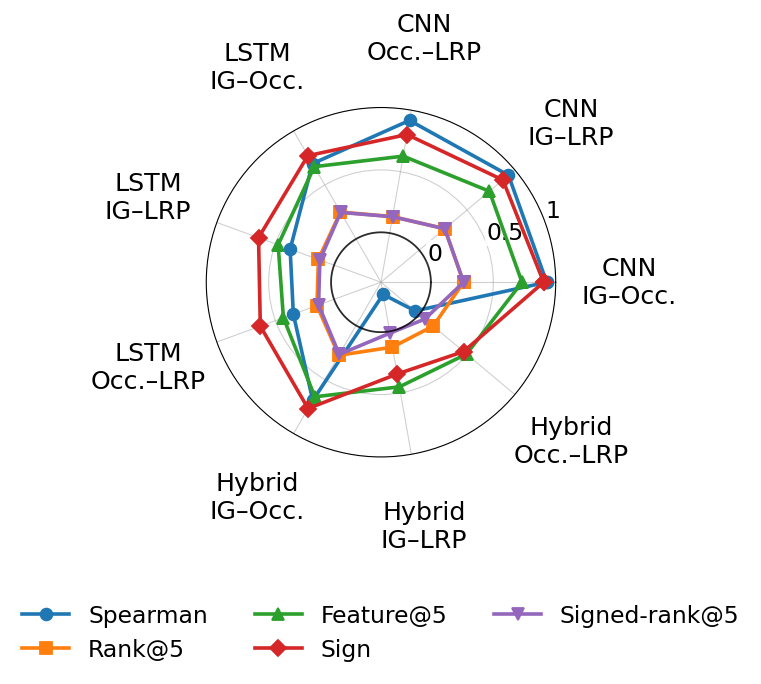

radar_cross_model


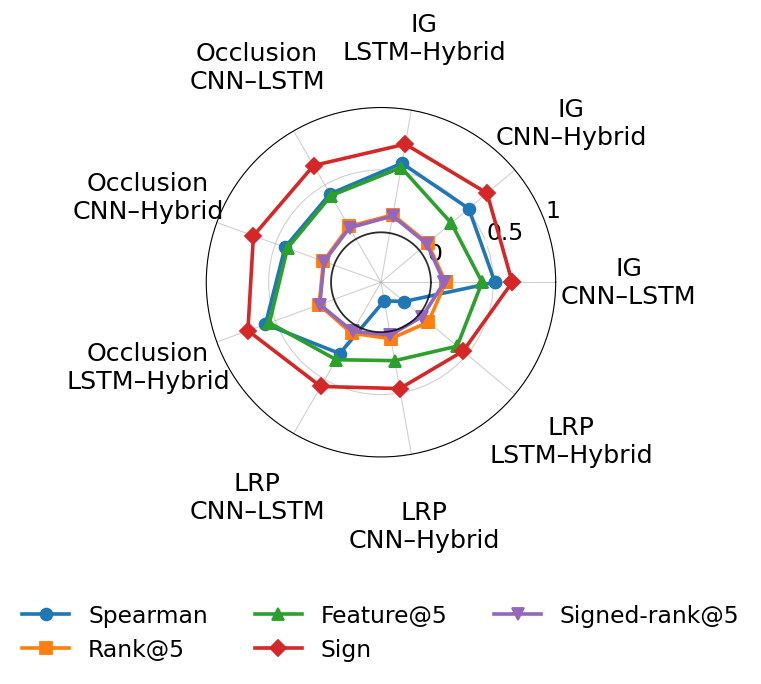

hist_within_spearman


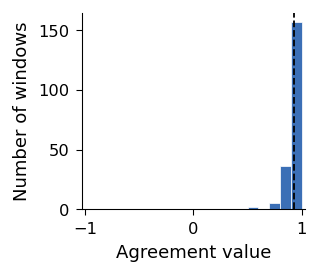

hist_cross_spearman


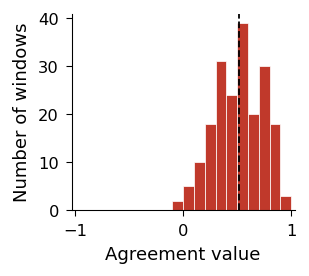

agg_heatmap_grid


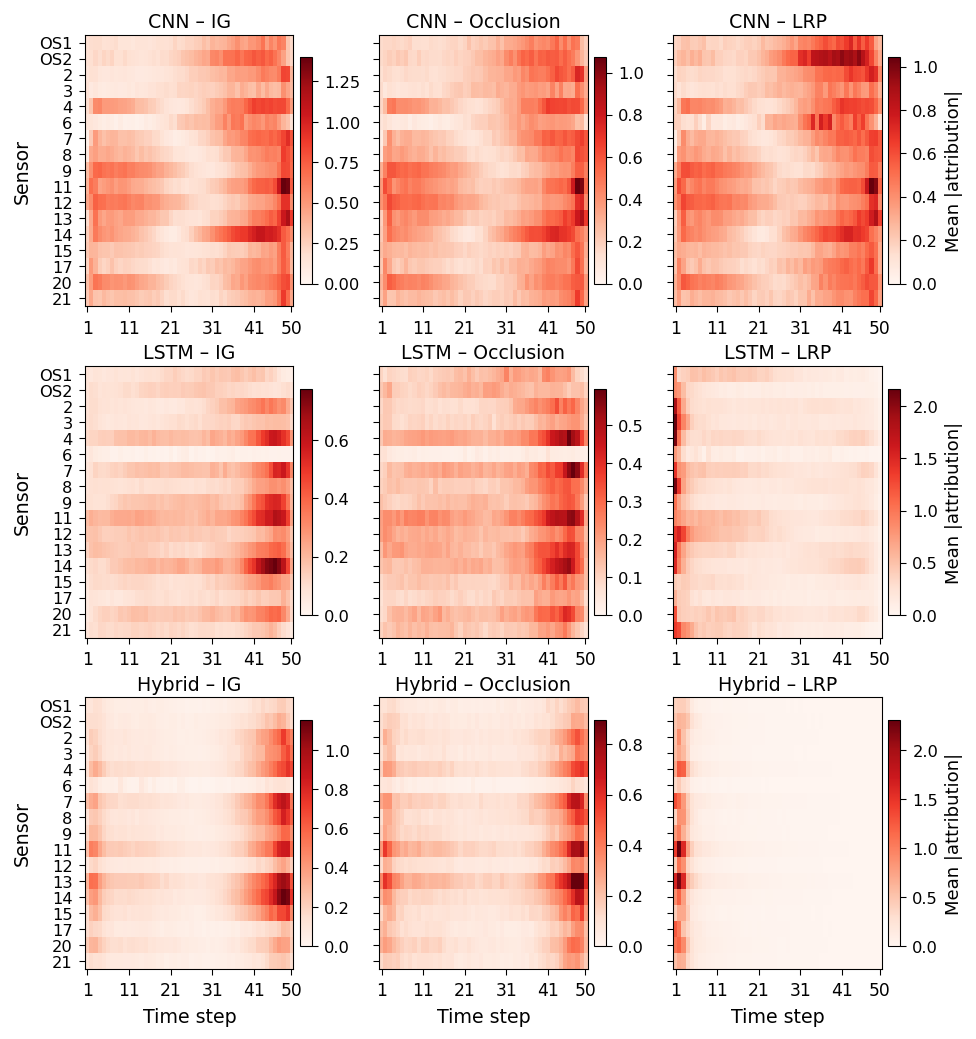

actmax_cnn


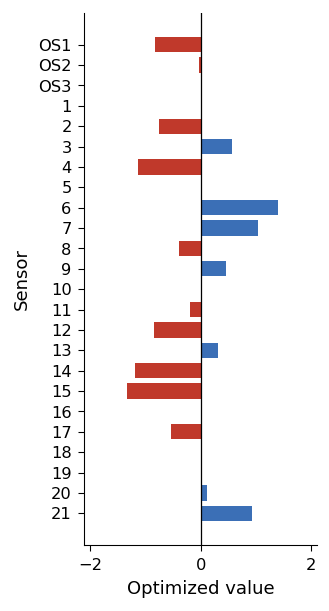

actmax_lstm


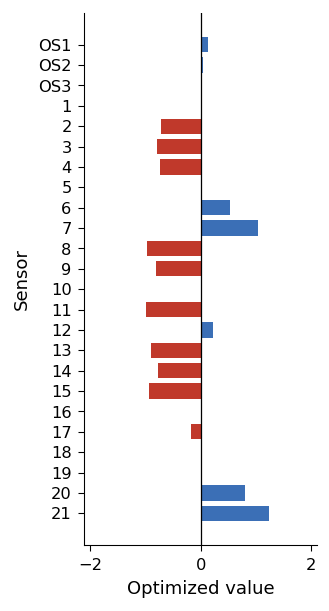

actmax_hybrid


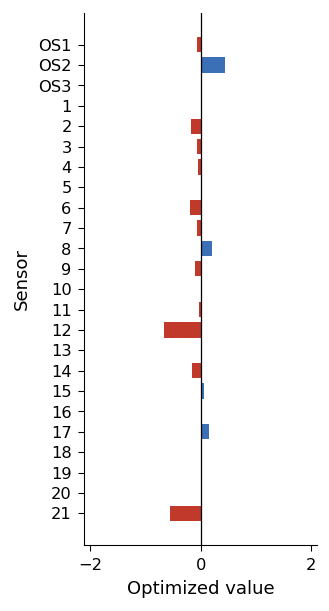

eval_sensitivity_hist


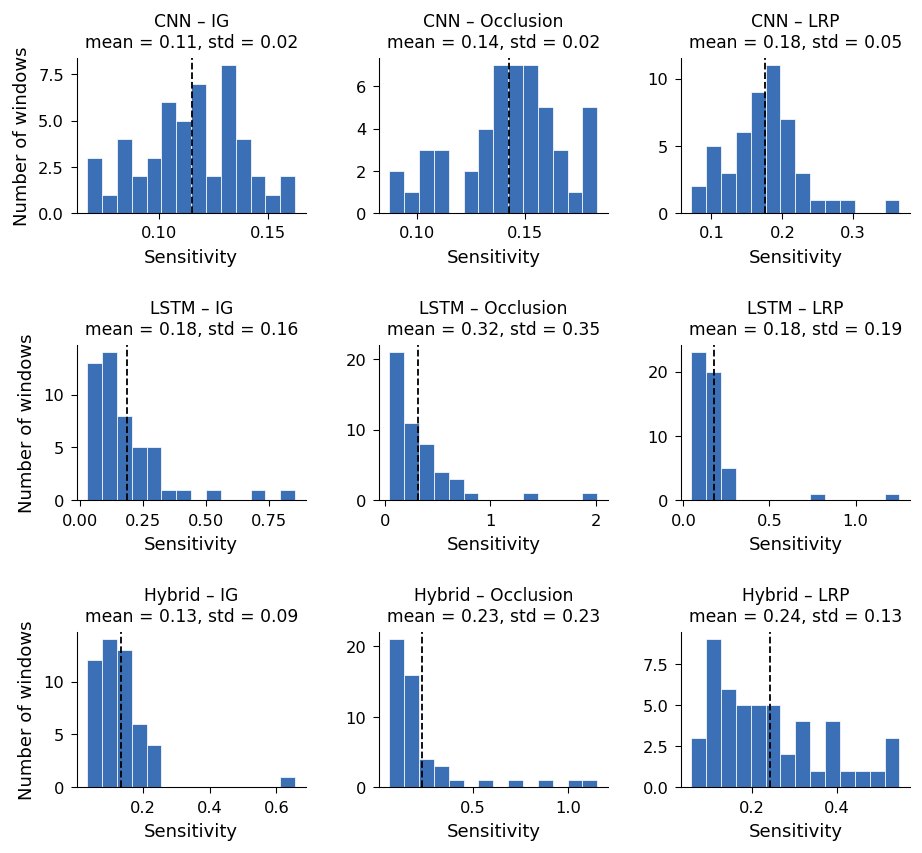

eval_infidelity_hist


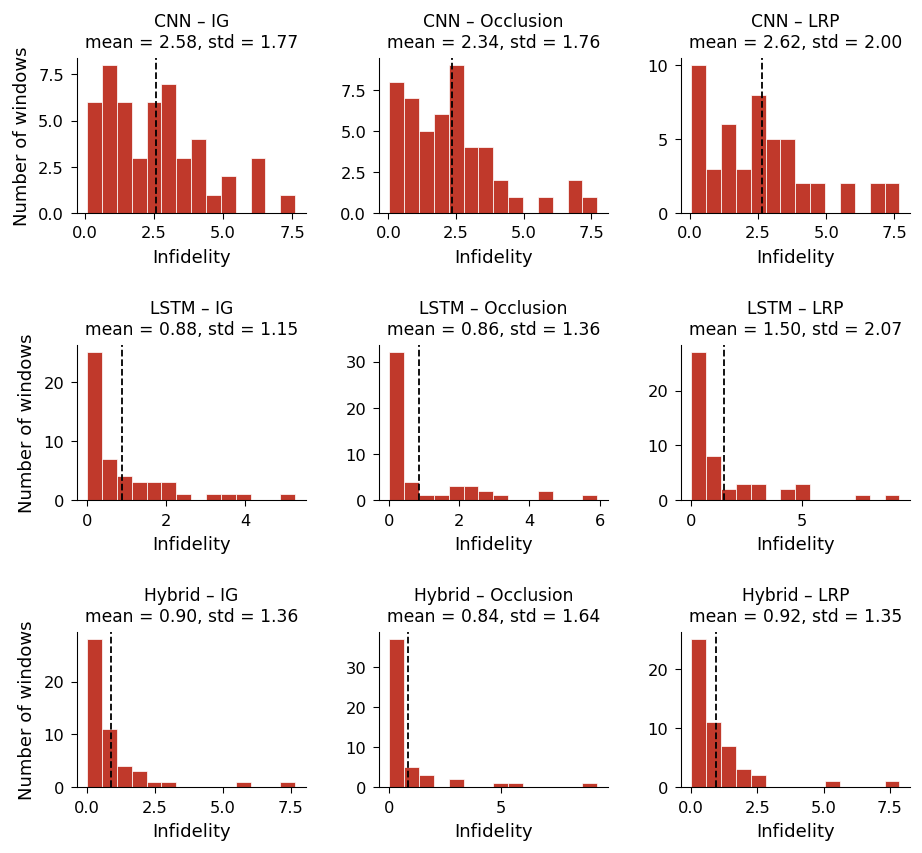

output_noise_cnn


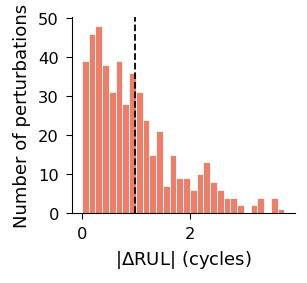

In [12]:
run("make_paper_assets.py", "--set", "active17")
for f in ["radar_within_model", "radar_cross_model", "hist_within_spearman", "hist_cross_spearman", "agg_heatmap_grid",
          "actmax_cnn", "actmax_lstm", "actmax_hybrid", "eval_sensitivity_hist", "eval_infidelity_hist", "output_noise_cnn"]:
    print(f)
    display(Image(filename=f"../results/paper/figures/{f}.png", width=520))

## 10. Check of the numbers in the paper
`verify_paper_numbers.py` reads the tables of `paper/main.tex` and compares every number with the results above, with the saved weights and with the survey. It should end with `ALL NUMBERS MATCH`.

In [13]:
run("verify_paper_numbers.py", "../paper/main.tex")

paper: ../paper/main.tex

Table 6                   45 numbers checked, 0 mismatches
Table 7                   45 numbers checked, 0 mismatches
Table 8                   36 numbers checked, 0 mismatches
Table 9                   72 numbers checked, 0 mismatches
Table 4                   33 numbers checked, 0 mismatches
Table 5                   24 numbers checked, 0 mismatches
Table 10                   7 numbers checked, 0 mismatches
Table 11                   6 numbers checked, 0 mismatches
Table 2 (trend arrows)    21 numbers checked, 0 mismatches

ALL NUMBERS MATCH

